# Data Cleaning — Raw Movies Dataset
**Dataset:** Movies dataset from the [vega-datasets](https://github.com/vega/vega-datasets) project (movie metadata, box-office numbers and IMDB / Rotten Tomatoes ratings). 3,201 rows × 16 columns.
**Why this dataset:** it is genuinely messy — heavy missing values, impossible dates, zero values that really mean "not recorded", inconsistent text, high-cardinality categories and extreme skew.
**Goal:** produce a clean, analysis-ready and model-ready dataset, and document the reasoning for every decision.
**Author:** Rishav Kumar

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid'); plt.rcParams['figure.figsize']=(9,5)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

raw = pd.read_json('movies.json')
before = raw.copy()          # untouched snapshot for the before/after comparison

## 1. Quality assessment of the raw data

In [2]:
print('Shape:', raw.shape)
raw.info(memory_usage='deep')

Shape: (3201, 16)
<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3200 non-null   object 
 1   US Gross                3194 non-null   float64
 2   Worldwide Gross         3194 non-null   float64
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   str    
 6   MPAA Rating             2596 non-null   str    
 7   Running Time min        1209 non-null   float64
 8   Distributor             2969 non-null   str    
 9   Source                  2836 non-null   str    
 10  Major Genre             2926 non-null   str    
 11  Creative Type           2755 non-null   str    
 12  Director                1870 non-null   str    
 13  Rotten Tomatoes Rating  2321 non-null   float64
 14  IMDB Rating             2988 non-

In [3]:
raw.head()

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,146083.0,146083.0,NaN,8000000.0,Jun 12 1998,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,1071.0
1,"First Love, Last Rites",10876.0,10876.0,NaN,300000.0,Aug 07 1998,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0
2,I Married a Strange Person,203134.0,203134.0,NaN,250000.0,Aug 28 1998,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0
3,Let's Talk About Sex,373615.0,373615.0,NaN,300000.0,Sep 11 1998,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN
4,Slam,1009819.0,1087521.0,NaN,1000000.0,Oct 09 1998,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0


In [4]:
miss = pd.DataFrame({'missing': raw.isna().sum(), 'pct': (raw.isna().mean()*100).round(1)}).sort_values('missing', ascending=False)
miss

,missing,pct
US DVD Sales,2637,82.4
Running Time min,1992,62.2
Director,1331,41.6
Rotten Tomatoes Rating,880,27.5
MPAA Rating,605,18.9
Creative Type,446,13.9
Source,365,11.4
Major Genre,275,8.6
Distributor,232,7.2
IMDB Rating,213,6.7


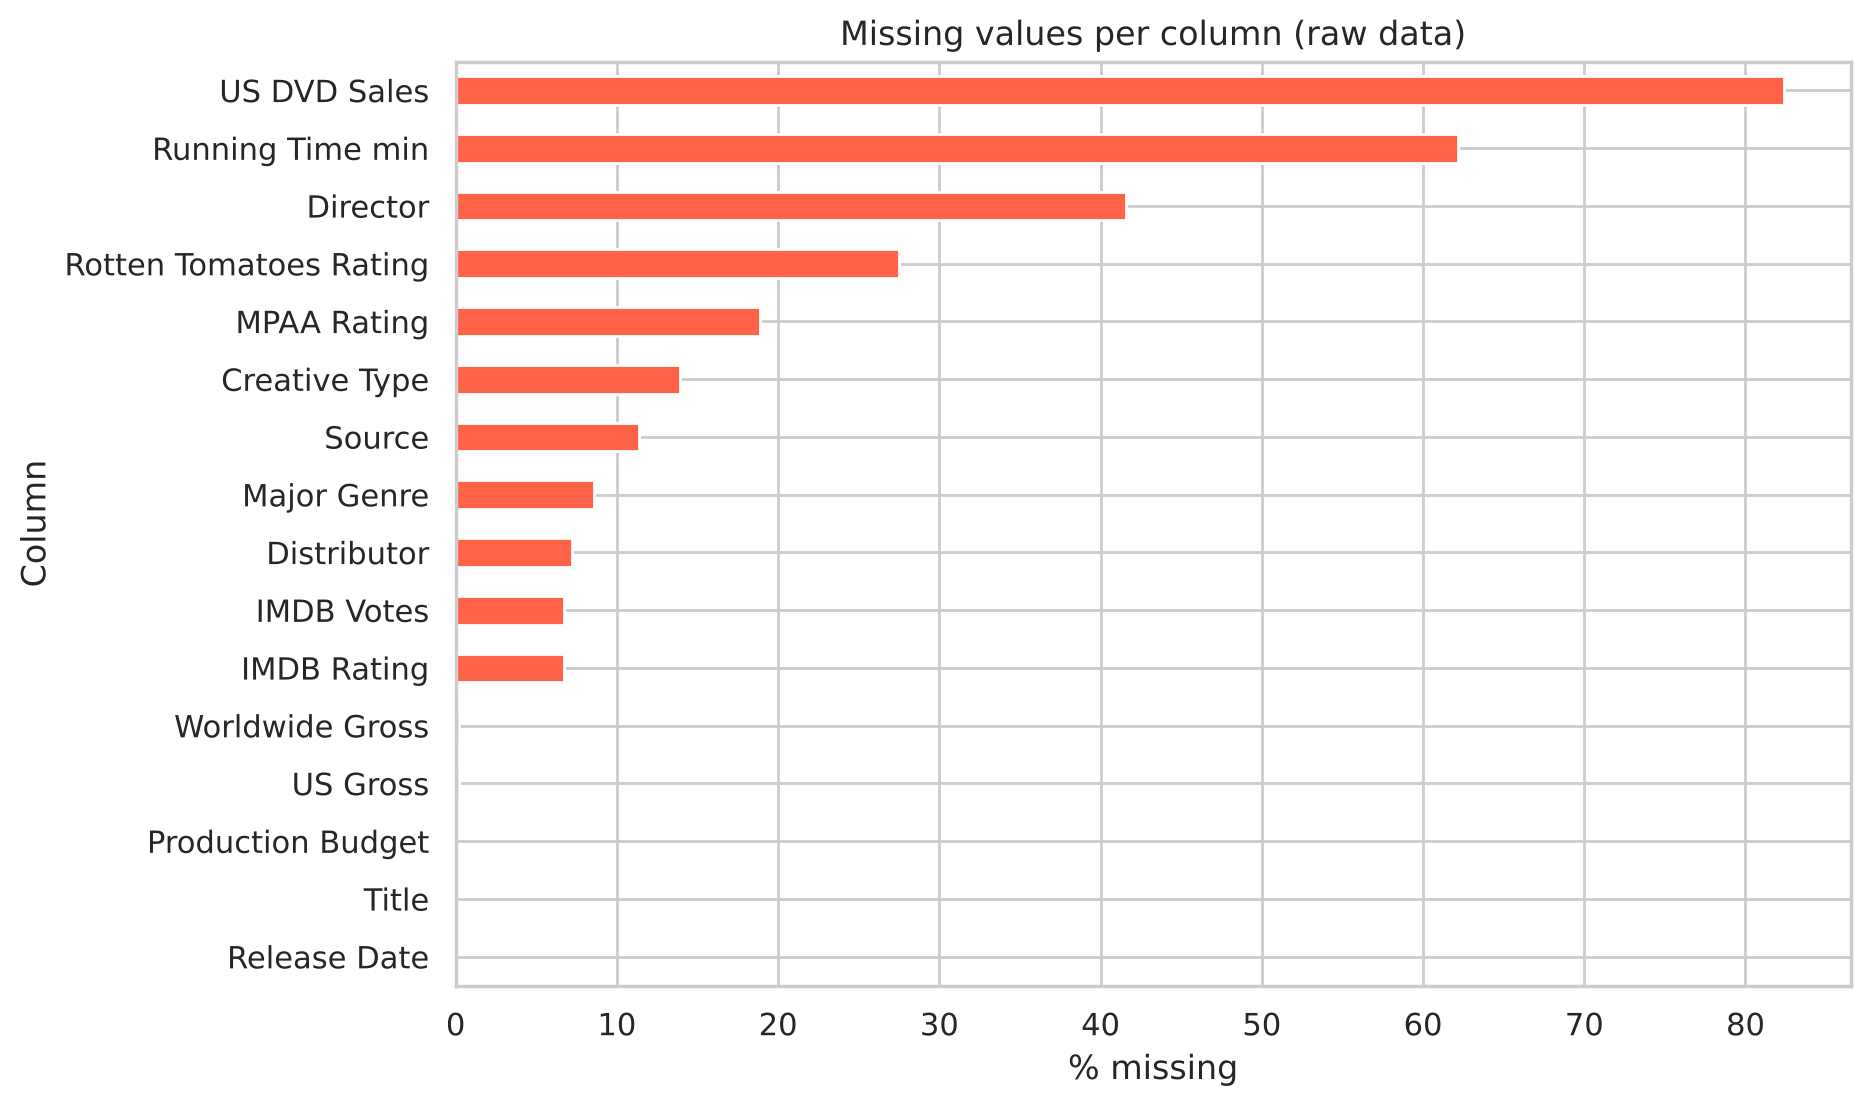

In [5]:
ax = miss['pct'].sort_values().plot.barh(color='tomato', figsize=(9,6))
ax.set_title('Missing values per column (raw data)'); ax.set_xlabel('% missing'); ax.set_ylabel('Column')
plt.show()

Almost every column has gaps, and several are badly affected: `US DVD Sales` (82% missing), `Running Time min` (62%), `Director` (42%), `Rotten Tomatoes Rating` (27%). Each needs its own decision.

In [6]:
print('Exact duplicate rows            :', raw.duplicated().sum())
print('Duplicate Title (any date)       :', raw.duplicated(subset='Title').sum())
print('Duplicate Title + Release Date   :', raw.duplicated(subset=['Title','Release Date']).sum())
print('Titles stored as numbers, not text:', raw['Title'].map(lambda x: isinstance(x,(int,float)) and pd.notna(x)).sum())
print('Example numeric titles            :', [x for x in raw['Title'] if isinstance(x,(int,float)) and pd.notna(x)][:6])
print()
print(raw['MPAA Rating'].value_counts(dropna=False))

Exact duplicate rows            : 0
Duplicate Title (any date)       : 24
Duplicate Title + Release Date   : 0
Titles stored as numbers, not text: 9
Example numeric titles            : [1776, 1941, 1408, 2012, 2046, 21]

MPAA Rating
R            1194
PG-13         865
NaN           605
PG            354
Not Rated      94
G              79
NC-17           8
Open            2
Name: count, dtype: int64


Other issues spotted so far:
- No exact duplicates, but 24 repeated titles — need to check whether they are true duplicates or different films (remakes).
- Mixed data types in `Title`: 9 film titles that are numbers (e.g. *1776*, *300*, *21*) are stored as integers instead of text, which would break any string operation.
- `MPAA Rating` contains an odd `Open` label and many `NaN`s.

In [7]:
d = pd.to_datetime(raw['Release Date'])
print('Release years range:', d.dt.year.min(), '-', d.dt.year.max())
print('Rows with release year > 2011 (dataset is from ~2010):', (d.dt.year>2011).sum())
raw[d.dt.year>2011][['Title','Release Date','Director']].head(8)

Release years range: 1928 - 2046
Rows with release year > 2011 (dataset is from ~2010): 22


,Title,Release Date,Director
9,Duel in the Sun,Dec 31 2046,NaN
15,Over the Hill to the Poorhouse,Sep 17 2020,NaN
16,Wilson,Aug 01 2044,NaN
26,"20,000 Leagues Under the Sea",Dec 24 2016,NaN
33,42nd Street,Mar 09 2033,NaN
85,Ben-Hur,Dec 30 2025,NaN
90,The Best Years of Our Lives,Nov 21 2046,William Wyler
102,The Big Parade,Jan 01 2025,King Vidor


The dataset was compiled around 2010, yet **22 films have release dates up to 2046** — e.g. *Ben-Hur* is shown as 2025 and *20,000 Leagues Under the Sea* as 2016. These are data-entry errors where the century is wrong (the real films are from 1925 and 1916 etc.).

In [8]:
print('US Gross == 0        :', (raw['US Gross']==0).sum())
print('Worldwide Gross == 0 :', (raw['Worldwide Gross']==0).sum())
print('Both grosses missing :', raw[['US Gross','Worldwide Gross']].isna().all(axis=1).sum())
print('Worldwide < US gross :', (raw['Worldwide Gross']<raw['US Gross']).sum())
raw[raw['Worldwide Gross']==0][['Title','Release Date','US Gross','Worldwide Gross','Production Budget']].head()

US Gross == 0        : 66
Worldwide Gross == 0 : 47
Both grosses missing : 7
Worldwide < US gross : 0


,Title,Release Date,US Gross,Worldwide Gross,Production Budget
19,12 Angry Men,Apr 13 1957,0.0,0.0,340000.0
21,1776,Nov 09 1972,0.0,0.0,4000000.0
48,Alice in Wonderland,Jul 28 1951,0.0,0.0,3000000.0
68,Barbarella,Oct 10 1968,0.0,0.0,9000000.0
94,Big Things,Dec 31 2009,0.0,0.0,50000.0


A gross of exactly 0 for classics like *12 Angry Men* is not a real box-office result; it means *not recorded*. Worldwide gross is never smaller than US gross, so there is no logical conflict apart from these zeros.

## 2. Duplicates

In [9]:
df = raw.copy()
# Standardise column names, fix the Title data type and strip whitespace first, so hidden duplicates become visible
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df['title'] = df['title'].map(lambda x: str(x) if pd.notna(x) else x)   # numeric titles (1776, 300...) -> text
for c in df.select_dtypes(['object','string']).columns:
    df[c] = df[c].str.strip()
print('Exact duplicates after cleaning text:', df.duplicated().sum())
dups = df[df.duplicated(subset='title', keep=False)].sort_values('title')
dups[['title','release_date','director','us_gross']].head(10)

Exact duplicates after cleaning text: 0


,title,release_date,director,us_gross
25,"20,000 Leagues Under the Sea",Dec 23 1954,Richard Fleischer,28200000.0
26,"20,000 Leagues Under the Sea",Dec 24 2016,NaN,8000000.0
2406,A Nightmare on Elm Street,Apr 30 2010,NaN,63075011.0
654,A Nightmare on Elm Street,Nov 09 1984,Wes Craven,25504513.0
48,Alice in Wonderland,Jul 28 1951,NaN,0.0
1138,Alice in Wonderland,Mar 05 2010,Tim Burton,334191110.0
67,Around the World in 80 Days,Oct 17 1956,NaN,42000000.0
1238,Around the World in 80 Days,Jun 16 2004,Frank Coraci,24004159.0
85,Ben-Hur,Dec 30 2025,NaN,9000000.0
86,Ben-Hur,Nov 18 1959,William Wyler,73000000.0


**Decision:** there are no true duplicate rows to remove. The repeated titles are different films with different release dates and grosses (e.g. *A Nightmare on Elm Street* 1984 vs 2010, *Alice in Wonderland* 1951 vs 2010), so removing them would delete real data. I still run `drop_duplicates()` as a safeguard.

In [10]:
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('Rows removed as duplicates:', n0-len(df))

Rows removed as duplicates: 0


## 3. Format and invalid-value fixes

### 3.1 Release date — fix wrong centuries

In [11]:
df['release_date'] = pd.to_datetime(df['release_date'])
bad = df['release_date'].dt.year > 2011
print('Rows with impossible future year:', bad.sum())
# Data-entry error: century is off by 100 years -> subtract 100 years
df.loc[bad, 'release_date'] = df.loc[bad, 'release_date'] - pd.DateOffset(years=100)
print('Year range after fix:', df['release_date'].dt.year.min(), '-', df['release_date'].dt.year.max())
df[bad][['title','release_date']].head(6)

Rows with impossible future year: 22
Year range after fix: 1915 - 2011


,title,release_date
9,Duel in the Sun,1946-12-31
15,Over the Hill to the Poorhouse,1920-09-17
16,Wilson,1944-08-01
26,"20,000 Leagues Under the Sea",1916-12-24
33,42nd Street,1933-03-09
85,Ben-Hur,1925-12-30


**Decision:** the dataset contains no film after 2011, so every year above that is a wrong century. Subtracting 100 years restores the true date (*Ben-Hur* → 1925, *42nd Street* → 1933). Dropping those 22 rows would have lost valid film data.

### 3.2 Zero gross values mean 'not recorded'

In [12]:
# A worldwide gross of 0 together with a US gross of 0 means no revenue data was recorded
no_rev = (df['us_gross'].fillna(0)==0) & (df['worldwide_gross'].fillna(0)==0)
print('Rows with no usable revenue data (0 or missing in both):', no_rev.sum())

Rows with no usable revenue data (0 or missing in both): 54


**Decision:** rows where both gross columns are 0 or missing carry no revenue information at all, and imputing revenue (the core business metric) would be fabricating data. They are **dropped**. Rows with `us_gross = 0` but a positive worldwide gross (foreign films that never opened in the US) are real, so they are **kept**.

In [13]:
df = df[~no_rev].reset_index(drop=True)
print('Shape after dropping rows with no revenue data:', df.shape)

Shape after dropping rows with no revenue data: (3147, 16)


### 3.3 Inconsistent MPAA rating labels

In [14]:
print(df['mpaa_rating'].value_counts(dropna=False))
df['mpaa_rating'] = df['mpaa_rating'].replace({'Open': 'Unknown'})

mpaa_rating
R            1184
PG-13         863
NaN           568
PG            350
Not Rated      93
G              79
NC-17           8
Open            2
Name: count, dtype: int64


`Open` is not a real MPAA rating (it marks films with no rating assigned), so it is merged with the missing values under one label, `Unknown`, which is handled in the next section.

## 4. Missing values — one decision per column

In [15]:
m = pd.DataFrame({'missing': df.isna().sum(), 'pct': (df.isna().mean()*100).round(1)})
m[m.missing>0].sort_values('missing', ascending=False)

,missing,pct
us_dvd_sales,2586,82.2
running_time_min,1938,61.6
director,1288,40.9
rotten_tomatoes_rating,841,26.7
mpaa_rating,568,18.0
creative_type,416,13.2
source,340,10.8
major_genre,247,7.8
distributor,203,6.5
imdb_rating,191,6.1


| Column | Missing | Strategy | Reason |
|---|---|---|---|
| `title` | 1 | **Drop row** | A film with no title cannot be identified or checked. Only 1 row. |
| `production_budget` | 1 | **Drop row** | One row; budget is a key numeric variable and a guessed value could distort it. |
| `us_dvd_sales` | ~82% | **Drop column** (keep a `has_dvd_sales` flag) | Far too sparse; DVD data exists only for popular releases (missing *not* at random), so imputing would invent data. The flag keeps the useful signal. |
| `running_time_min` | ~62% | **Drop column** | More than half missing; imputing the median would flatten the whole column. |
| `director` | ~42% | **Drop column** | 40%+ missing and ~550 unique names — too sparse and high-cardinality to encode usefully. |
| `rotten_tomatoes_rating` | ~27% | **Median imputation** + missing flag | Numeric, bounded 0–100, no extreme outliers; median is robust. A flag keeps the information that it was missing. |
| `imdb_rating`, `imdb_votes` | ~7% | **Median imputation** + missing flag | Ratings are roughly symmetric; votes are heavily right-skewed, so the median (not the mean) is the right centre. |
| `mpaa_rating`, `distributor`, `source`, `major_genre`, `creative_type` | 7–19% | **Constant `'Unknown'`** | Categorical; the mode would wrongly assign e.g. every missing genre to Drama. A separate category is honest and lets the model learn from missingness. |

In [16]:
# 1) Drop rows with no title / no budget
df = df.dropna(subset=['title','production_budget']).reset_index(drop=True)

# 2) Flags first (before values are filled), then drop columns
df['has_dvd_sales'] = df['us_dvd_sales'].notna().astype(int)
df['rt_missing']    = df['rotten_tomatoes_rating'].isna().astype(int)
df['imdb_missing']  = df['imdb_rating'].isna().astype(int)
df = df.drop(columns=['us_dvd_sales','running_time_min','director'])

# 3) Median imputation for numeric columns
for c in ['rotten_tomatoes_rating','imdb_rating','imdb_votes']:
    print(f'{c}: median = {df[c].median():.1f}')
    df[c] = df[c].fillna(df[c].median())

# 4) Constant for categorical columns
for c in ['mpaa_rating','distributor','source','major_genre','creative_type']:
    df[c] = df[c].fillna('Unknown')

print('\nRemaining missing values:', df.isna().sum().sum())
print('Shape:', df.shape)

rotten_tomatoes_rating: median = 55.0
imdb_rating: median = 6.4
imdb_votes: median = 15370.0

Remaining missing values: 0
Shape: (3145, 16)


## 5. Outlier detection and decisions

In [17]:
def iqr_bounds(s):
    q1, q3 = s.quantile([.25,.75]); i = q3-q1
    return q1-1.5*i, q3+1.5*i

cols = ['production_budget','us_gross','worldwide_gross','imdb_votes','imdb_rating','rotten_tomatoes_rating']
rows = []
for c in cols:
    lo, hi = iqr_bounds(df[c]); n = ((df[c]<lo)|(df[c]>hi)).sum()
    z = ((df[c]-df[c].mean())/df[c].std()).abs()
    rows.append([c, round(lo), round(hi), n, round(n/len(df)*100,1), (z>3).sum()])
pd.DataFrame(rows, columns=['column','IQR lower','IQR upper','IQR outliers','% rows','|z|>3'])

,column,IQR lower,IQR upper,IQR outliers,% rows,|z|>3
0,production_budget,-47000000,97000000,171,5.4,76
1,us_gross,-70050000,132750000,246,7.8,74
2,worldwide_gross,-126307197,233891563,312,9.9,66
3,imdb_votes,-37230,76430,287,9.1,70
4,imdb_rating,3,9,74,2.4,34
5,rotten_tomatoes_rating,-9,119,0,0.0,0


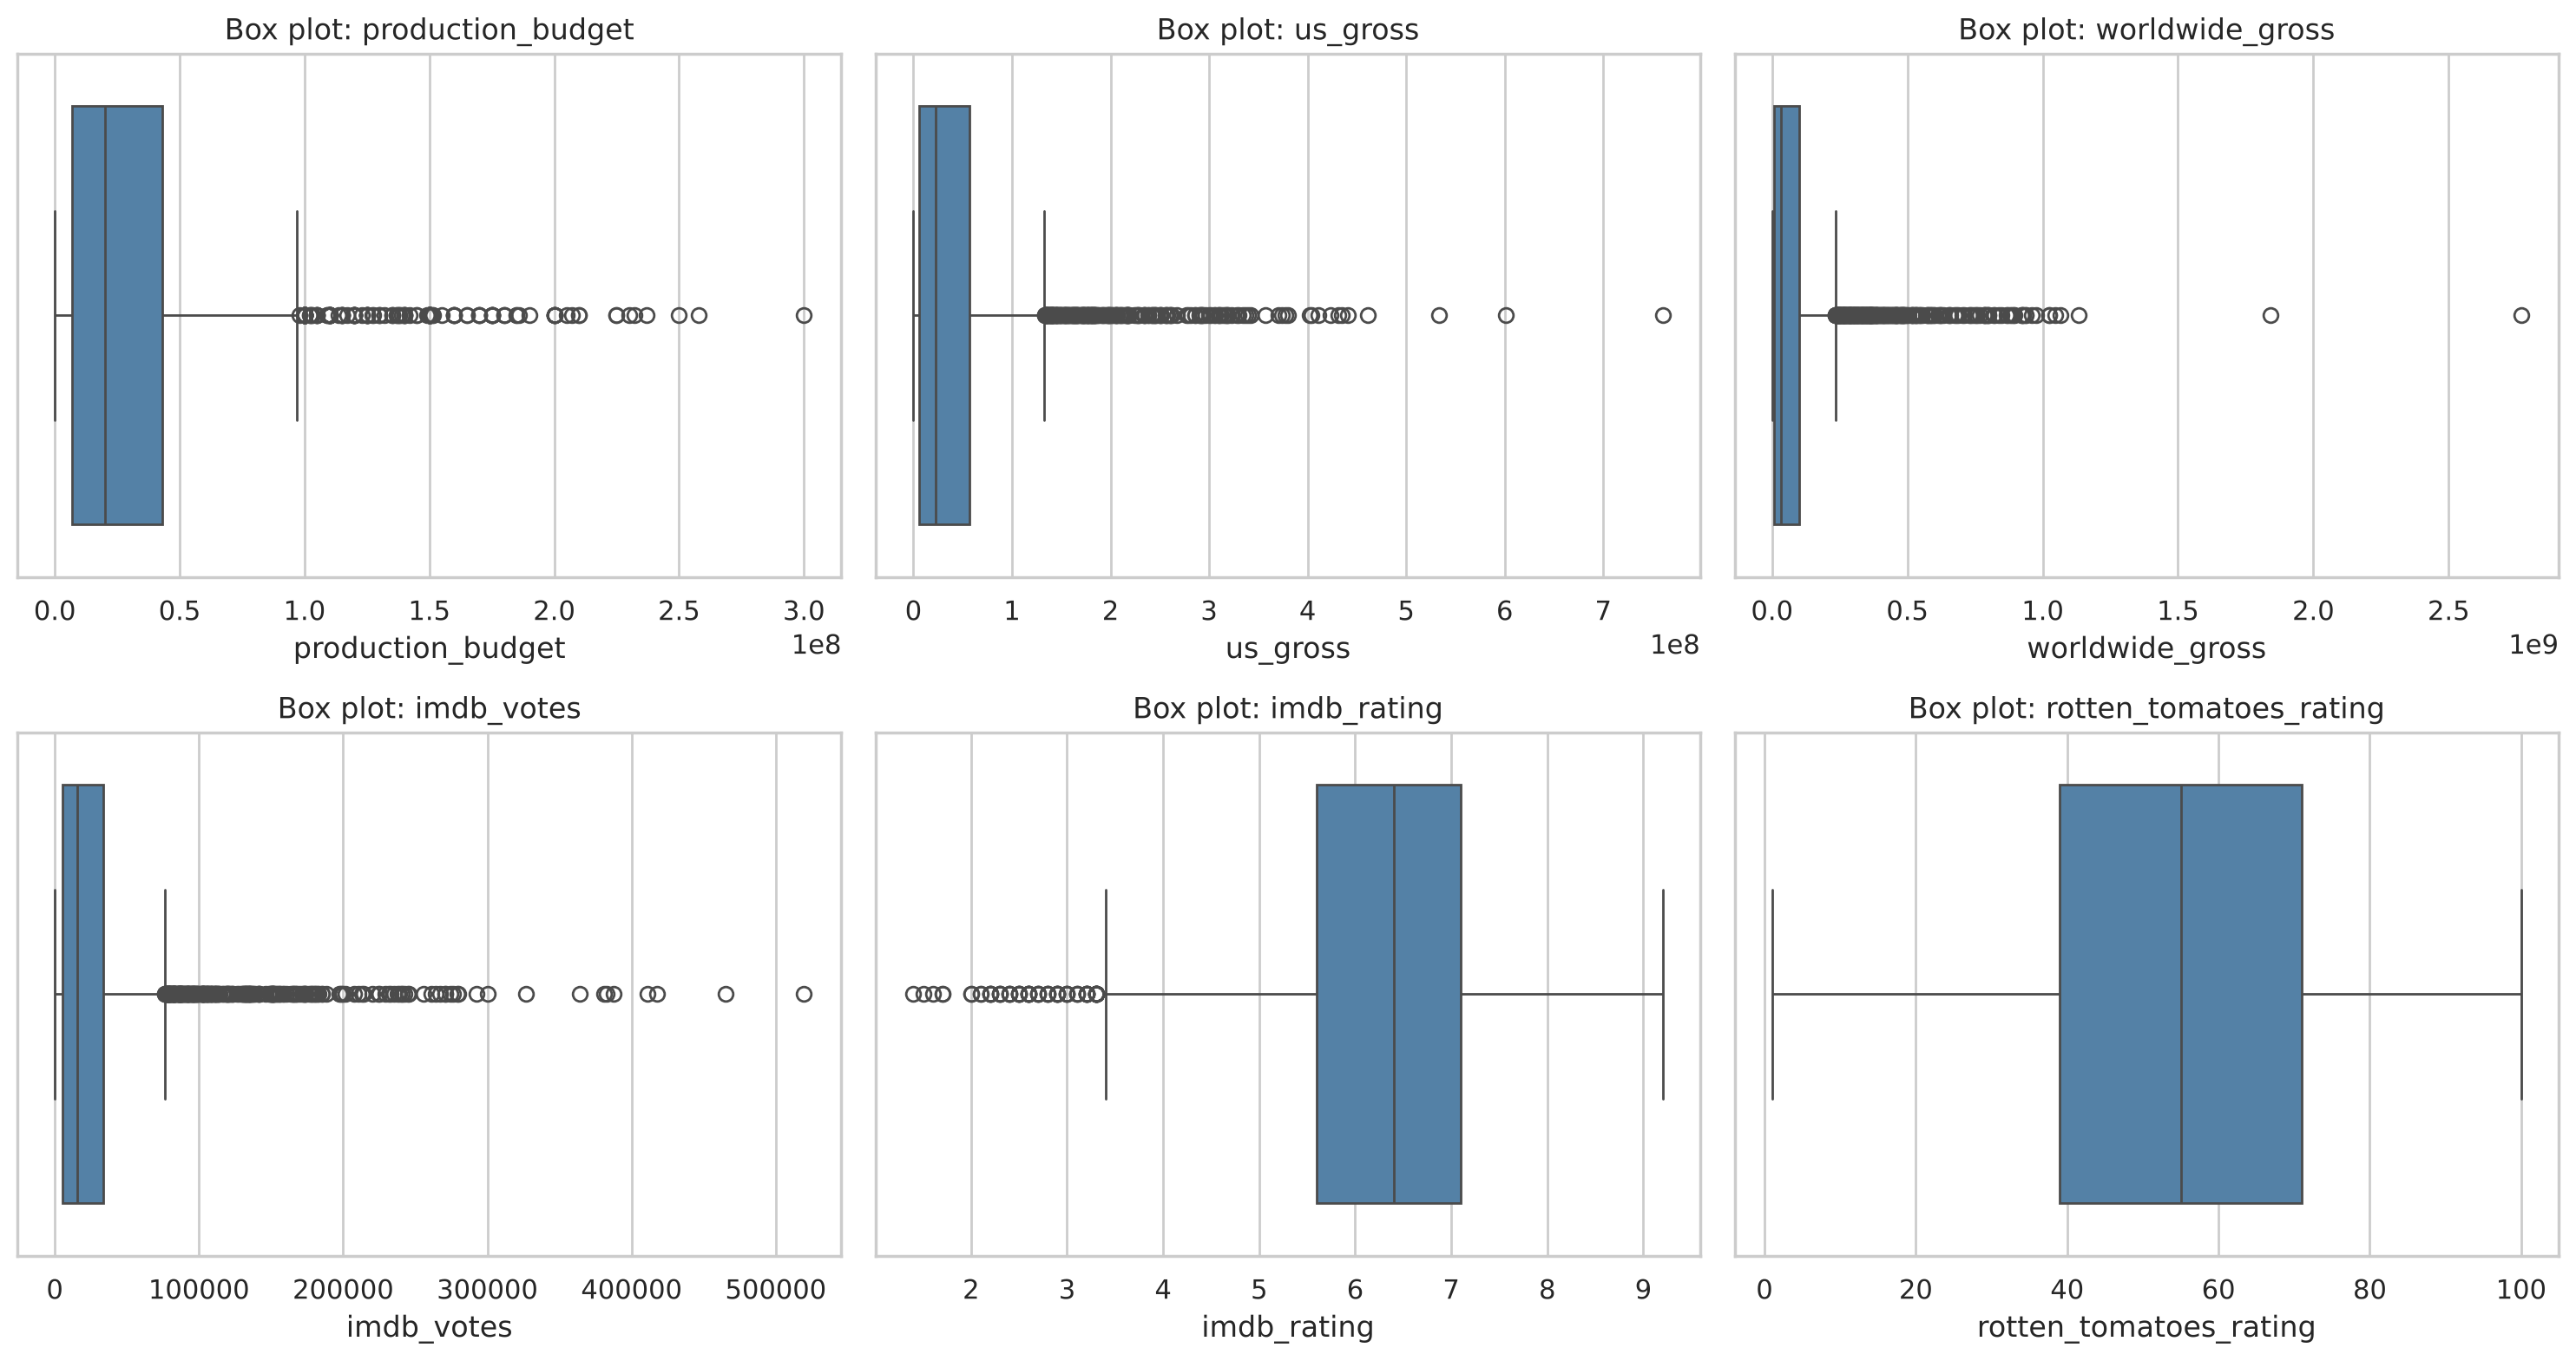

In [18]:
fig, ax = plt.subplots(2,3, figsize=(15,8))
for a, c in zip(ax.ravel(), cols):
    sns.boxplot(x=df[c], ax=a, color='steelblue'); a.set_title(f'Box plot: {c}'); a.set_xlabel(c)
plt.tight_layout(); plt.show()

The box plots show a clear pattern: the money and vote columns are extremely right-skewed with many IQR "outliers", while the rating columns have almost none.

**Decision per column** (an outlier is removed only if it is an error, not just extreme):
- `production_budget`, `us_gross`, `worldwide_gross`: the flagged points are real blockbusters (e.g. *Avatar*, *Titanic*). Removing them would delete the most important films, so they are **kept**. The skew is handled with a `log1p` transform for modelling.
- Very small budgets (e.g. $218 for *Tarnation*, $1,100 for *My Date With Drew*) look like typos but are **documented, true micro-budget films**, so they are **kept**.
- `imdb_votes`: popular films legitimately have 500k votes; **kept**, log-transformed.
- `imdb_rating`, `rotten_tomatoes_rating`: values are within valid ranges (1.4–9.2 and 1–100), so nothing is changed.
- The real *errors* in this dataset were not statistical outliers but impossible values: the wrong-century dates (fixed in 3.1) and the zero gross values (handled in 3.2).

                                         title  production_budget
2457  Pirates of the Caribbean: At World's End        300000000.0
2770                              Spider-Man 3        258000000.0
1924    Harry Potter and the Half-Blood Prince        250000000.0
                              title  production_budget
2866                      Tarnation              218.0
2337              My Date With Drew             1100.0
775   Return to the Land of Wonders             5000.0


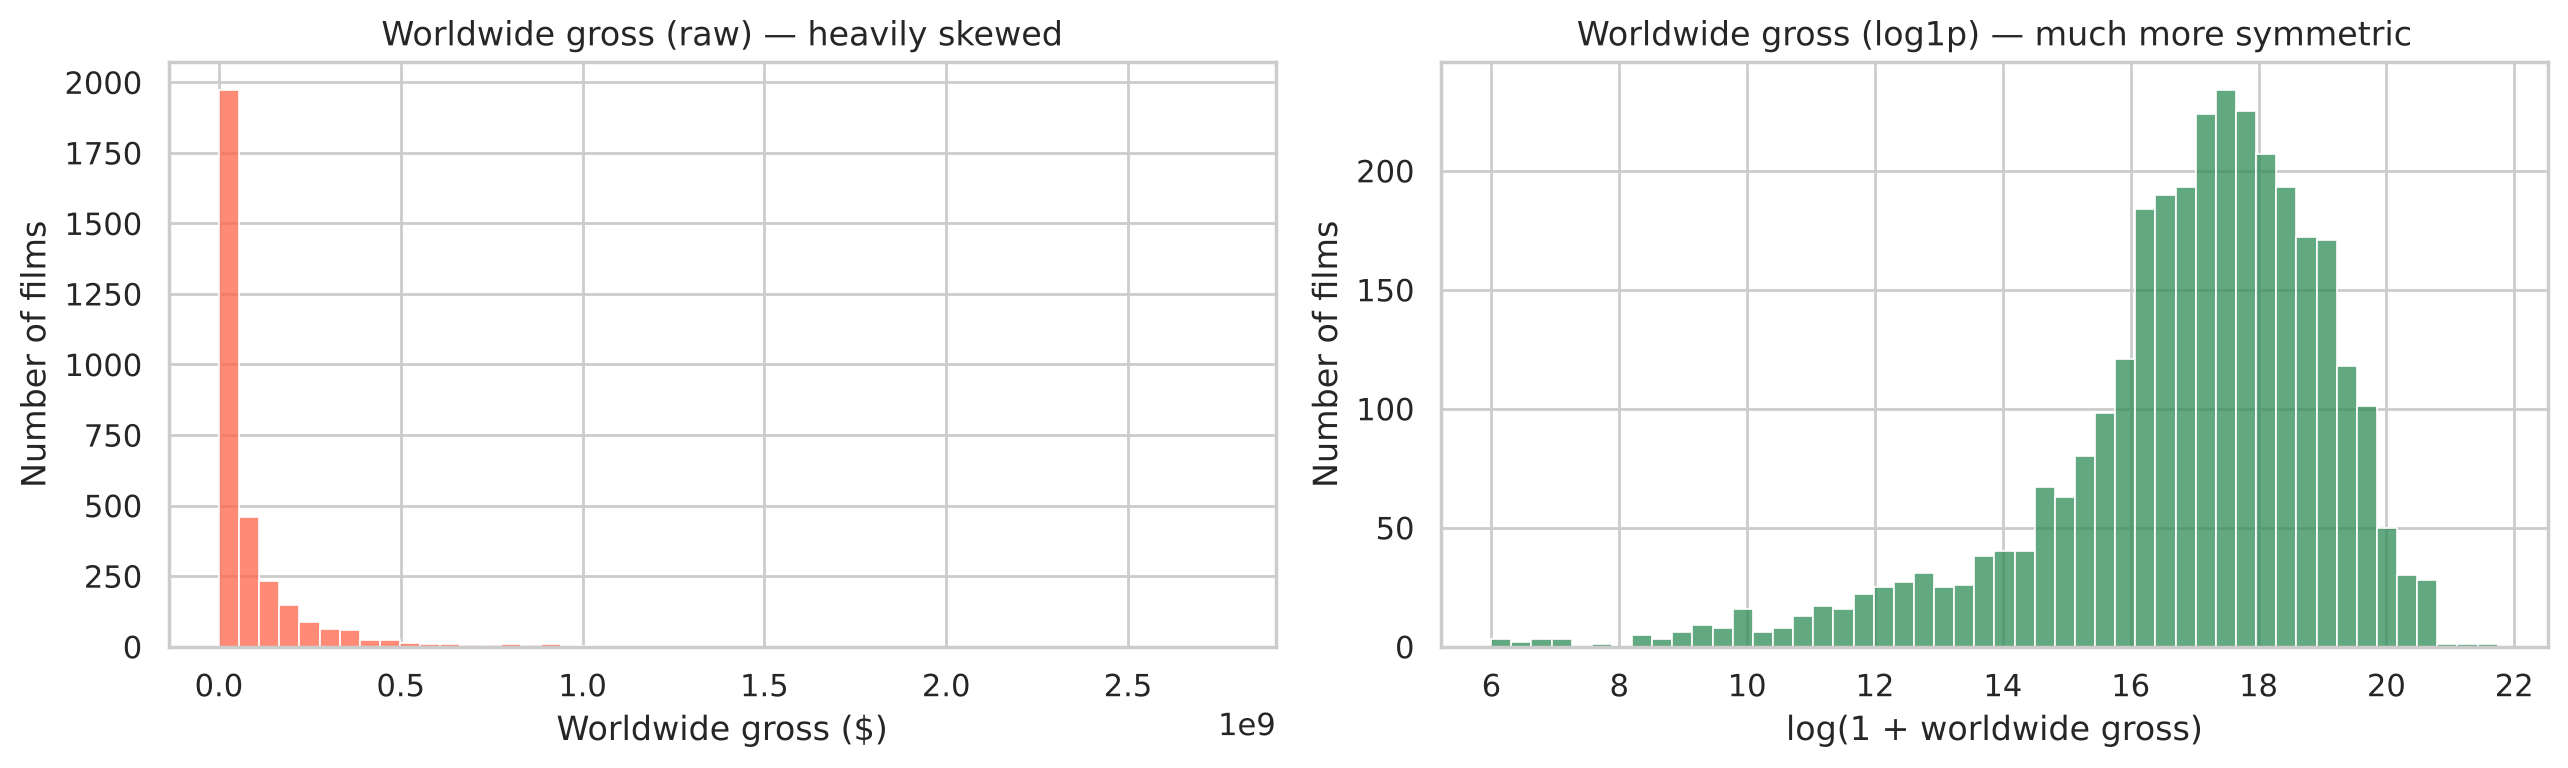

In [19]:
print(df.nlargest(3,'production_budget')[['title','production_budget']])
print(df.nsmallest(3,'production_budget')[['title','production_budget']])
for c in ['production_budget','us_gross','worldwide_gross','imdb_votes']:
    df[f'log_{c}'] = np.log1p(df[c])
fig, ax = plt.subplots(1,2, figsize=(13,4))
sns.histplot(df['worldwide_gross'], bins=50, ax=ax[0], color='tomato'); ax[0].set_title('Worldwide gross (raw) — heavily skewed'); ax[0].set_xlabel('Worldwide gross ($)'); ax[0].set_ylabel('Number of films')
sns.histplot(df['log_worldwide_gross'], bins=50, ax=ax[1], color='seagreen'); ax[1].set_title('Worldwide gross (log1p) — much more symmetric'); ax[1].set_xlabel('log(1 + worldwide gross)'); ax[1].set_ylabel('Number of films')
plt.tight_layout(); plt.show()

## 6. Encoding categorical variables

In [20]:
for c in ['mpaa_rating','major_genre','source','creative_type','distributor']:
    print(f'{c:15s} unique values: {df[c].nunique()}')

mpaa_rating     unique values: 7
major_genre     unique values: 13
source          unique values: 19
creative_type   unique values: 10
distributor     unique values: 168


Each variable gets the encoding that suits it:

| Variable | Encoding | Reason |
|---|---|---|
| `mpaa_rating` | **Ordinal** (G=1 < PG=2 < PG-13=3 < R=4 < NC-17=5; Not Rated / Unknown = 0) | The ratings have a natural order of content restriction. |
| `major_genre` | **One-hot** | 12 unordered categories, few enough for one-hot. |
| `creative_type` | **One-hot** | Unordered, 10 categories. |
| `source` | **Group rare categories into 'Other', then one-hot** | 19 categories, many with under 2% of rows; grouping avoids dozens of near-empty columns. |
| `distributor` | **Frequency encoding** | ~170 unordered values — one-hot would add ~170 columns; the share of films per distributor keeps one numeric column. |
| `release_date` | **Numeric parts** (year, month) | Models can't use raw dates; month captures seasonality (summer blockbusters). |

In [21]:
enc = df.copy()

# Ordinal: MPAA rating
mpaa_map = {'G':1,'PG':2,'PG-13':3,'R':4,'NC-17':5,'Not Rated':0,'Unknown':0}
enc['mpaa_rating_ord'] = enc['mpaa_rating'].map(mpaa_map)

# Frequency encoding: distributor
freq = enc['distributor'].value_counts(normalize=True)
enc['distributor_freq'] = enc['distributor'].map(freq)

# Group rare 'source' categories (<2% of rows) into 'Other'
share = enc['source'].value_counts(normalize=True)
rare = share[share<0.02].index
enc['source'] = enc['source'].replace({r:'Other' for r in rare})

# Date parts
enc['release_year']  = enc['release_date'].dt.year
enc['release_month'] = enc['release_date'].dt.month

# One-hot: genre, creative type, source
enc = pd.get_dummies(enc, columns=['major_genre','creative_type','source'], prefix=['genre','ctype','src'], dtype=int)

# Drop columns that are now redundant or not model-ready (title kept as an identifier)
enc = enc.drop(columns=['mpaa_rating','distributor','release_date'])
print('Encoded shape:', enc.shape)
enc.head()

Encoded shape: (3145, 49)


,title,us_gross,worldwide_gross,production_budget,rotten_tomatoes_rating,imdb_rating,imdb_votes,has_dvd_sales,rt_missing,imdb_missing,log_production_budget,log_us_gross,log_worldwide_gross,log_imdb_votes,mpaa_rating_ord,...,ctype_Fantasy,ctype_Historical Fiction,ctype_Kids Fiction,ctype_Multiple Creative Types,ctype_Science Fiction,ctype_Super Hero,ctype_Unknown,src_Based on Book/Short Story,src_Based on Comic/Graphic Novel,src_Based on Real Life Events,src_Based on TV,src_Original Screenplay,src_Other,src_Remake,src_Unknown
0,The Land Girls,146083.0,146083.0,8000000.0,55.0,6.1,1071.0,0,1,0,15.894952,11.891937,11.891937,6.977281,4,...,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
1,"First Love, Last Rites",10876.0,10876.0,300000.0,55.0,6.9,207.0,0,1,0,12.611541,9.294406,9.294406,5.337538,4,...,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
2,I Married a Strange Person,203134.0,203134.0,250000.0,55.0,6.8,865.0,0,1,0,12.429220,12.221626,12.221626,6.763885,0,...,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
3,Let's Talk About Sex,373615.0,373615.0,300000.0,13.0,6.4,15370.0,0,0,1,12.611541,12.830984,12.830984,9.640238,0,...,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
4,Slam,1009819.0,1087521.0,1000000.0,62.0,3.4,165.0,0,0,0,13.815512,13.825283,13.899412,5.111988,4,...,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


In [22]:
print('Non-numeric columns left (should only be title):', list(enc.select_dtypes(exclude='number').columns))
print('Missing values in encoded data:', enc.isna().sum().sum())

Non-numeric columns left (should only be title): ['title']
Missing values in encoded data: 0


## 7. Before vs after comparison

In [23]:
comp = pd.DataFrame({
    'Before (raw)':   [before.shape[0], before.shape[1], int(before.isna().sum().sum()), int(before.duplicated().sum()), before.memory_usage(deep=True).sum()//1024],
    'After (cleaned)':[df.shape[0],     df.shape[1],     int(df.isna().sum().sum()),     int(df.duplicated().sum()),     df.memory_usage(deep=True).sum()//1024],
    'After (encoded)':[enc.shape[0],    enc.shape[1],    int(enc.isna().sum().sum()),    int(enc.duplicated().sum()),    enc.memory_usage(deep=True).sum()//1024]},
    index=['Rows','Columns','Total missing values','Duplicate rows','Memory (KB)'])
comp

,Before (raw),After (cleaned),After (encoded)
Rows,3201,3145,3145
Columns,16,20,49
Total missing values,9205,0,0
Duplicate rows,0,0,0
Memory (KB),1644,1472,1353


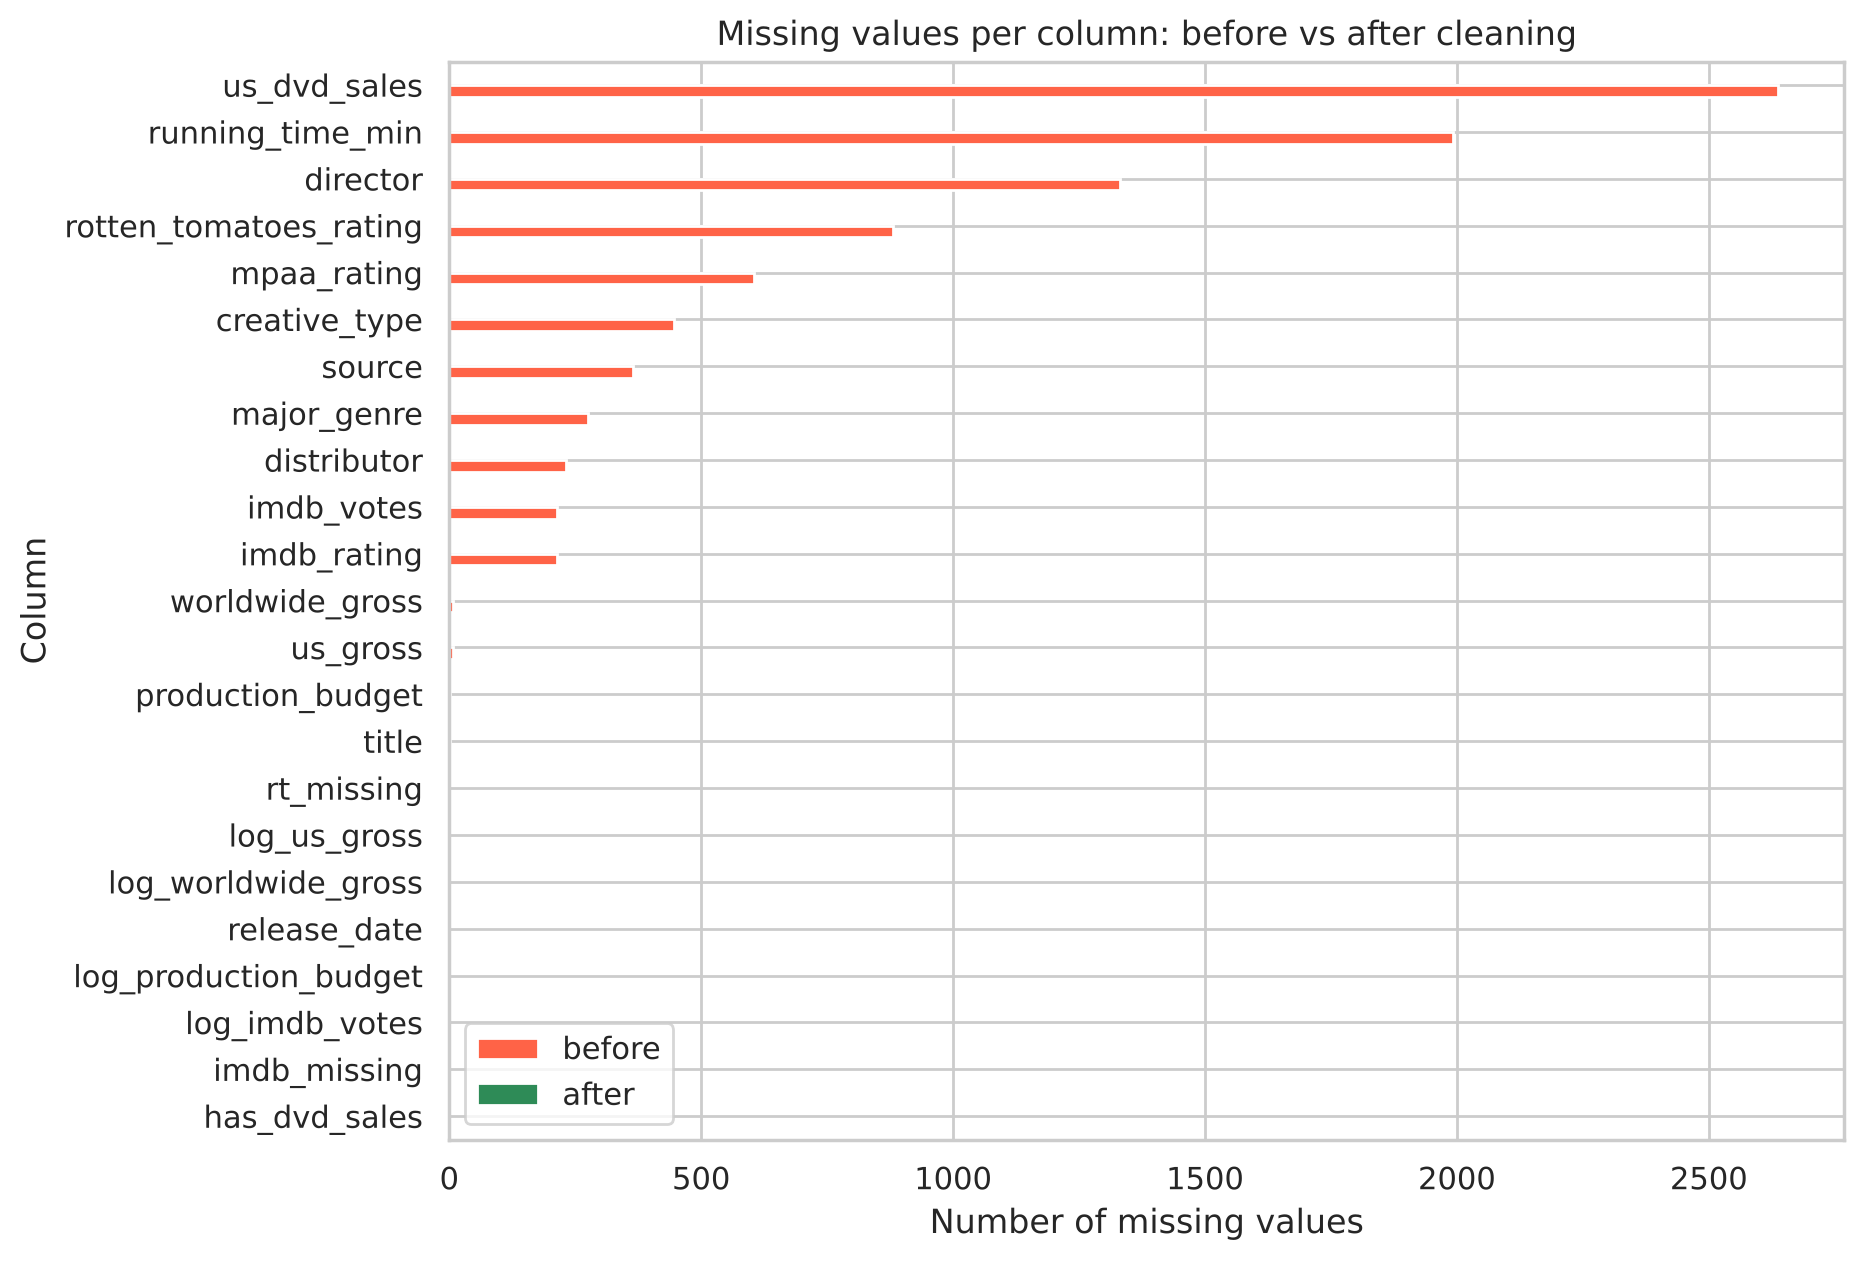

In [24]:
b = before.isna().sum(); a = df.rename(columns=lambda c:c).isna().sum()
b.index = b.index.str.lower().str.replace(' ','_')
cmp = pd.DataFrame({'before': b, 'after': a}).fillna(0)
ax = cmp.sort_values('before').plot.barh(figsize=(9,7), color=['tomato','seagreen'])
ax.set_title('Missing values per column: before vs after cleaning'); ax.set_xlabel('Number of missing values'); ax.set_ylabel('Column')
plt.show()

In [25]:
sb = before[['US Gross','Worldwide Gross','Production Budget','IMDB Rating','IMDB Votes','Rotten Tomatoes Rating']].describe().T
sb.index = sb.index.str.lower().str.replace(' ','_')
sa = df[sb.index].describe().T
pd.concat({'BEFORE': sb[['count','mean','50%','std','min','max']], 'AFTER': sa[['count','mean','50%','std','min','max']]}, axis=1).round(2)

BEFORE                                                               AFTER                                                            
                         count         mean         50%           std    min           max   count         mean         50%           std    min           max
us_gross                3194.0  44002085.16  22019465.5  6.255531e+07    0.0  7.601676e+08  3145.0  44668406.80  22730924.0  6.280179e+07    0.0  7.601676e+08
worldwide_gross         3194.0  85343400.14  31168926.5  1.499473e+08    0.0  2.767891e+09  3145.0  86651621.01  32223424.0  1.507373e+08  401.0  2.767891e+09
production_budget       3200.0  31069171.45  20000000.0  3.558591e+07  218.0  3.000000e+08  3145.0  31379564.37  20000000.0  3.568573e+07  218.0  3.000000e+08
imdb_rating             2988.0         6.28         6.4  1.250000e+00    1.4  9.200000e+00  3145.0         6.29         6.4  1.210000e+00    1.4  9.200000e+00
imdb_votes              2988.0     29908.64     15106.0  4.493758e+04   18.0  5.195410e+05  3145.0     29250.28     15370.0  4.382892e+04   18.0  5.195410e+05
rotten_tomatoes_rating  2321.0        54.34        55.0  2.808000e+01    1.0  1.000000e+02  3145.0        54.45        55.0  2.403000e+01    1.0  1.000000e+02

After cleaning, the missing-value count drops to zero and the worldwide gross no longer has impossible zeros (its minimum is now a real value). The `count` for the rating columns rises because the gaps were filled, and the mean/median barely move — showing that median imputation did not distort the distributions.

In [26]:
print('Release year range before:', pd.to_datetime(before['Release Date']).dt.year.max(), '(max)  ->  after:', df['release_date'].dt.year.max(), '(max)')

Release year range before: 2046 (max)  ->  after: 2010 (max)


## 8. Save the cleaned data

In [27]:
df.to_csv('movies_clean.csv', index=False)
enc.to_csv('movies_encoded.csv', index=False)
print('Saved movies_clean.csv', df.shape, 'and movies_encoded.csv', enc.shape)

Saved movies_clean.csv (3145, 20) and movies_encoded.csv (3145, 49)


## 9. Summary of cleaning decisions
1. **Duplicates:** no exact duplicates; repeated titles are different films (remakes), so they were kept. `drop_duplicates()` was run as a safeguard.
2. **Invalid values:** fixed 22 wrong-century release dates (up to year 2046); treated gross = 0 as "not recorded" and dropped the rows with no revenue data in either gross column.
3. **Missing values:** a different strategy per column — dropped 2 near-empty rows, dropped 3 columns that were too sparse (DVD sales, running time, director) while keeping a flag for DVD data, median-imputed the numeric ratings and votes with missing flags, and used an `'Unknown'` category for categorical gaps.
4. **Outliers:** detected with IQR, z-score and box plots; kept all real blockbusters and micro-budget films, and handled skew with a `log1p` transform instead of deleting data.
5. **Encoding:** ordinal for MPAA rating, one-hot for genre / creative type / grouped source, frequency encoding for the ~170 distributors, numeric year and month for dates.
6. **Data types:** numeric titles such as *1776* and *300* were converted from integers to text.
7. **Result:** zero missing values, zero duplicates, correct dates, and a fully numeric dataset (`movies_encoded.csv`) ready for modelling.